### CNN Demo 

In [6]:
import numpy as np
import matplotlib.pyplot as plt

#### Create a simple white square with black edges

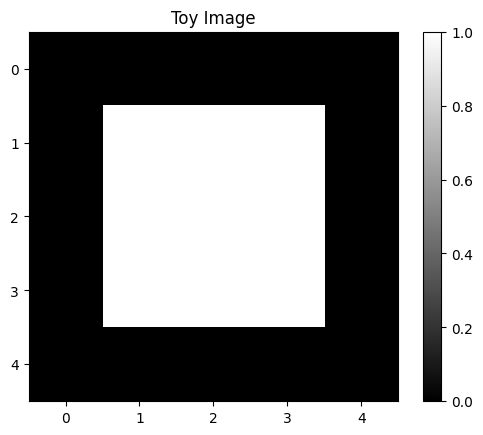

In [7]:
# Small toy image
image = np.array([  #1 is white, 0 is black
    [0,0,0,0,0],
    [0,1,1,1,0],
    [0,1,1,1,0],
    [0,1,1,1,0],
    [0,0,0,0,0]
], dtype=float)

plt.imshow(image, cmap="gray")
plt.title("Toy Image")
plt.colorbar()
plt.show()


#### Write a function convolve2d that takes an image and a kernel (aka filter). It pads the image around and then slides the kernel to produce the output. 

In [2]:
def convolve2d(image, kernel): #image and kernel are np.arrays
    h, w = image.shape  #image height and width
    kh, kw = kernel.shape #kernel height and width

    pad_h = kh // 2 # padding height is half the kernel height
    pad_w = kw // 2  # paddingwidth is half the kernel width

    padded = np.pad(image,
                    ((pad_h,pad_h),(pad_w,pad_w)),
                    mode='constant')   #add extra values around the boundaries of array

    output = np.zeros_like(image)  #initialize output with 0s.

    for r in range(h):
        for c in range(w):
            region = padded[r:r+kh, c:c+kw]   #select the range from the image to be blurred
            output[r,c] = np.sum(region * kernel)  #multiply with kernel and add 

    return output


## Blur Filter

A blur filter averages nearby pixels. It is formed by the convolution that averages a given square of values. In numpy we can do this with np.ones((n,n))/(n*n)

In [8]:
blur_filter = np.ones((3,3))/9
print( blur_filter)

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


In [9]:
blurred = convolve2d(image, blur_filter)
print(blurred)

[[0.11111111 0.22222222 0.33333333 0.22222222 0.11111111]
 [0.22222222 0.44444444 0.66666667 0.44444444 0.22222222]
 [0.33333333 0.66666667 1.         0.66666667 0.33333333]
 [0.22222222 0.44444444 0.66666667 0.44444444 0.22222222]
 [0.11111111 0.22222222 0.33333333 0.22222222 0.11111111]]


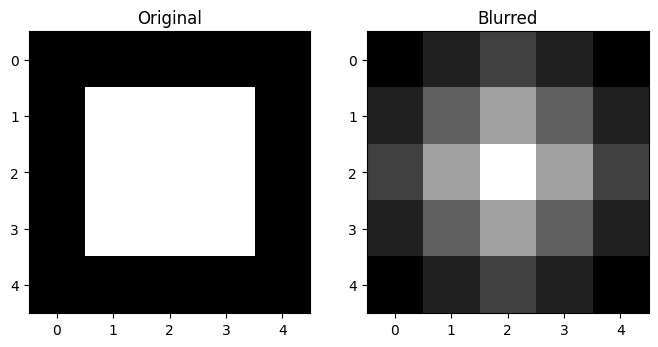

In [10]:
fig, ax = plt.subplots(1,2, figsize=(8,4))
ax[0].imshow(image, cmap="gray")
ax[0].set_title("Original")

ax[1].imshow(blurred, cmap="gray")
ax[1].set_title("Blurred")

plt.show()